# Generating Music with an Anticipatory Music Transformer

## Set up the machine

We use the fluidsynth library to synthesize audio from MIDI.

In [1]:
!apt install fluidsynth

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  at-spi2-common at-spi2-core fluid-soundfont-gm gsettings-desktop-schemas
  libatk-bridge2.0-0t64 libatk1.0-0t64 libatspi2.0-0t64 libb2-1
  libdouble-conversion3 libevdev2 libfluidsynth3 libgtk-3-0t64 libgtk-3-bin
  libgtk-3-common libgudev-1.0-0 libinput-bin libinput10 libinstpatch-1.0-2
  libmd4c0 libmtdev1t64 libpipewire-0.3-0t64 libpipewire-0.3-common
  libproxy1v5 libqt6core6t64 libqt6dbus6t64 libqt6gui6t64 libqt6network6t64
  libqt6opengl6t64 libqt6qml6 libqt6qmlmodels6 libqt6quick6
  libqt6waylandclient6 libqt6waylandcompositor6
  libqt6waylandeglclienthwintegration6
  libqt6waylandeglcompositorhwintegration6 libqt6widgets6t64
  libqt6wlshellintegration6 librsvg2-common libspa-0.2-modules libts0t64
  libwacom-common libwacom9 libwayland-server0 libwebrtc-audio-processing1
  libxcb-icccm4 libxcb-image0 libxcb-keysyms1 libxcb-render

Load the anticipation repository and install requirements.

In [2]:
import os

if not os.path.exists("anticipation"):
    !git clone https://github.com/jthickstun/anticipation.git

%pip install ./anticipation

%pip install --only-binary=tokenizers \
    "numpy>=2.1,<3" \
    "matplotlib>=3.9" \
    "mido==1.2.10" \
    "midi2audio==0.1.1" \
    "tqdm" \
    "transformers==4.49.0" \
    "tokenizers==0.21.4"

Cloning into 'anticipation'...
remote: Enumerating objects: 2779, done.
remote: Counting objects: 100% (433/433), done.
remote: Compressing objects: 100% (124/124), done.
remote: Total 2779 (delta 348), reused 316 (delta 309), pack-reused 2346 (from 2)
Receiving objects: 100% (2779/2779), 62.21 MiB | 25.21 MiB/s, done.
Resolving deltas: 100% (1928/1928), done.
Processing ./anticipation
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for anticipation: filename=anticipation-1.0-py3-none-any.whl size=18733 sha256=30d6559faeb663c998e4f99975091f837aef398350fce15e2fbe492126d14804
  Stored in directory: /tmp/pip-ephem-wheel-cache-w8yfmt8n/wheels/b1/30/e1/5f1f06d0c0f3b59cd9bdc9c45402e622d2ee65c41d0ddb1eba
Successfully built anticipation
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 30.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 60.1 MB/s  0:00:00
   ━━━━━

## Set up the runtime environment

In [3]:
import sys,time

import midi2audio
import transformers
from transformers import AutoModelForCausalLM

from IPython.display import Audio

from anticipation import ops
from anticipation.sample import generate
from anticipation.tokenize import extract_instruments
from anticipation.convert import events_to_midi,midi_to_events
from anticipation.visuals import visualize
from anticipation.config import *
from anticipation.vocab import *

In [4]:
SMALL_MODEL = 'stanford-crfm/music-small-800k'     # faster inference, worse sample quality
MEDIUM_MODEL = 'stanford-crfm/music-medium-800k'   # slower inference, better sample quality
LARGE_MODEL = 'stanford-crfm/music-large-800k'     # slowest inference, best sample quality

# load an anticipatory music transformer
model = AutoModelForCausalLM.from_pretrained(SMALL_MODEL).cuda()

# a MIDI synthesizer
fs = midi2audio.FluidSynth('/usr/share/sounds/sf2/FluidR3_GM.sf2')

# the MIDI synthesis script
def synthesize(fs, tokens):
    mid = events_to_midi(tokens)
    mid.save('tmp.mid')
    fs.midi_to_audio('tmp.mid', 'tmp.wav')
    return 'tmp.wav'

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/512M [00:00<?, ?B/s]

## Simple Interaction with the Anticipatory Music Transformer

### Unconditional generation

Let's begin by generating some unconditional music from the model. We achieve this by calling the `generate` function with `start_time=0` and `end_time=10`, asking the model to generate 10 seconds of music starting from time 0. The `top_p` nucleus sampling parameter controls how conservative sampling will be: lower values will tend to promote more boring, repetitive generation whereas higher values might encourage the model to be too experimental.

In [5]:
length = 10
unconditional_tokens = generate(model, start_time=0, end_time=length, top_p=.98)
Audio(synthesize(fs, unconditional_tokens))

 97%|█████████▋| 968/1000 [00:09<00:00, 103.59it/s]


### Prompted generation

We can use the music generated in the previous cell as a prompt to generate a longer segment of music. A natural interactive paradigm for music composition is to interatively ask the model to generate a proposal for the next for few seconds of music, and either accept this proposal and continue or reject the proposal and ask the model to try again.

This control flow is illustrated by the following figure:

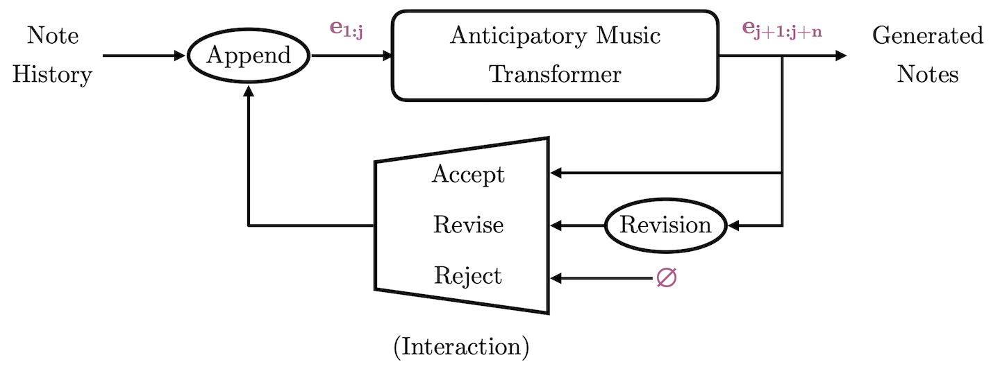

In [6]:
# Step 1: initialize the prompt (history)
history = unconditional_tokens.copy()

We prompt the model by specifying `inputs`, and ask the model to continue generating music, starting from the end of the previous prompt (`start_time=length`). In this example, we ask the model to generate an additional 5 seconds of music.

In [7]:
# Step 2: generate n seconds of music following the prompt
# re-run this cell immediate to reject the proposal
# or run the next cell to accept the proposal

n = 5

proposal = generate(model, start_time=length, end_time=length+n, inputs=history, top_p=0.98)
Audio(synthesize(fs, proposal))

 45%|████▍     | 224/500 [00:02<00:02, 106.71it/s]


After generating a candidate continuation `proposal`, we can choose to either accept this proposal (running the following cell to append the proposed continuation to the prompt) or reject the proposal (run the previous cell again).

In [8]:
# Step 3: accept the proposal
history = proposal
length += n

# re-run Step 2 to continue generating music

We can save the resulting music to a MIDI file.

In [9]:
mid = events_to_midi(proposal)
mid.save('prompted.mid')

## Loading your own MIDI

You can load your own MIDI as follows. Here, we synthesize the first 30 seconds of the loaded MIDI file by clipping the loaded sequence of events. The `ops.clip` function takes a list of `events`, a `start_time`, and an `end_time`, and returns the events in the interval [`start_time`,`end_time`].



In [10]:
events = midi_to_events('anticipation/examples/strawberry.mid')
Audio(synthesize(fs, ops.clip(events, 0, 30)))

Here's another example of clipping. This time, we clip 16 seconds of music starting 41 seconds into the music. The clipping operation simply discards events outside the specified region; often we will want to translate this clip to start from time 0. We can do this using `ops.translate`.

For the clip operation, we specified time in units of seconds. Time in our models is quantized at a much finer rate (10ms quantization). To be precise about timing, we can specify time using this fine-grained quantization. By specifying the `seconds=False` flag to `ops.min_time`, we retrieve the minimum time in the `segment` measured in 10ms resolution. Many of the utilities in the `ops` library provide an option time to be specified in either seconds or 100ths of a second.

In [11]:
segment = ops.clip(events, 41, 41+16)
segment = ops.translate(segment, -ops.min_time(segment, seconds=False))
Audio(synthesize(fs, segment))

### Span Infilling

We can use anticipation to infill a span of time. To do this, we treat the history (in this case, the first 6 seconds) as a prompt, and the future (the
last 5 seconds) as anticipated events. We mark anticipated events as a control by adding CONTROL_OFFSET to each item in the sequence. We can use the `ops.combine` method to recombine a sequence of events and control events.



In [12]:
history = ops.clip(segment, 0, 6, clip_duration=False)
anticipated = [CONTROL_OFFSET + tok for tok in ops.clip(segment, 11, 16, clip_duration=False)]
Audio(synthesize(fs, ops.combine(history, anticipated)))

To infill the missing span, we specify the anticipated events at the end of the span using the `controls` input to the `generate` function.

In [13]:
inpainted = generate(model, 6, 11, inputs=history, controls=anticipated, top_p=.95)
Audio(synthesize(fs, ops.combine(inpainted, anticipated)))

 96%|█████████▌| 480/500 [00:03<00:00, 129.46it/s]


### Accompaniment

Now let's see how to generate an accompaniment given a melodic line. We use the `extract_instruments` method to extract the melodic instrument (in this case, MIDI instrument code 53) from the music.

In [14]:
segment = ops.clip(events, 41, 41+20)
segment = ops.translate(segment, -ops.min_time(segment, seconds=False))

print(ops.get_instruments(segment).keys())
events, melody = extract_instruments(segment, [53])
Audio(synthesize(fs, melody))

dict_keys([29, 0, 35, 128, 53])


We are going to prompt the model using a 5-second clip from the beginning of the segment, plus the melody for the full 20-second segment. Here's what the prompt sounds like.

In [15]:
history = ops.clip(events, 0, 5, clip_duration=False)
Audio(synthesize(fs, history + melody))

And we generate an accompaniment, conditioning on 5 seconds of `history` and accompanying the subsequent 15 seconds `melody`, which we condition on as anticipated controls.

In [16]:
accompaniment = generate(model, 5, 20, inputs=history, controls=melody, top_p=.95, debug=False)
output = ops.clip(ops.combine(accompaniment, melody), 0, 20, clip_duration=True)
Audio(synthesize(fs, output))

 48%|████▊     | 717/1500 [00:00<00:00, 1044.66it/s]


## A Richer Interactive Control Flow

To create the co-compositions featured in Example 3 of the accompanying [blog post](https://crfm.stanford.edu/2023/06/14/anticipatory-music-transformer.html?idx=1#demo-example), we used a control flow that combines the iterative interaction flow described above together with melodic control inputs.

This modified control flow is illustrated by the following Figure:

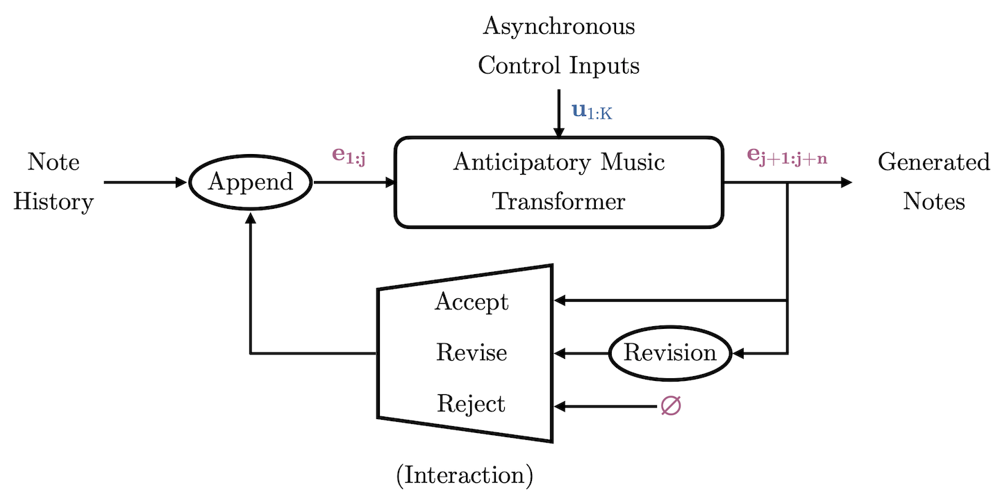

### Loading the initial note history and controls

First we load an initial MIDI to start our editing process:

In [17]:
events = midi_to_events('anticipation/examples/strawberry.mid')
segment = ops.clip(events, 41, 41+45)
segment = ops.translate(segment, -ops.min_time(segment, seconds=False))
Audio(synthesize(fs, segment))

We extract the melody to use as control inputs:

In [18]:
print(ops.get_instruments(segment))
events, melody = extract_instruments(segment, [53])
Audio(synthesize(fs, melody))

defaultdict(<class 'int'>, {29: 42, 0: 49, 35: 19, 128: 172, 53: 68, 43: 17, 117: 88, 61: 10, 104: 7})


And we extract the first 5 seconds to use as a prompt:

In [19]:
length = 5
prompt = ops.clip(events, 0, length, clip_duration=False)
Audio(synthesize(fs, prompt))

### The control loop

**Generate** new events (re-run this cell to reject the previous proposal)

In [20]:
n = 5              # choose how many seconds of music to generate
nucleus_p = 0.98   # choose a nucleus sampling probability

proposal = generate(model, start_time=length, end_time=length+n, inputs=prompt, controls=melody, top_p=nucleus_p)

 67%|██████▋   | 333/500 [00:02<00:01, 134.79it/s]


**Inspect** the proposed output

In [21]:
offset = 0   # an offset for the audio preview (set this to > 0 to clip the beginning of the sequence)

output = ops.clip(ops.combine(proposal, melody), offset, length+n, clip_duration=True)
output = ops.translate(output, -ops.min_time(output, seconds=False))
Audio(synthesize(fs, output))

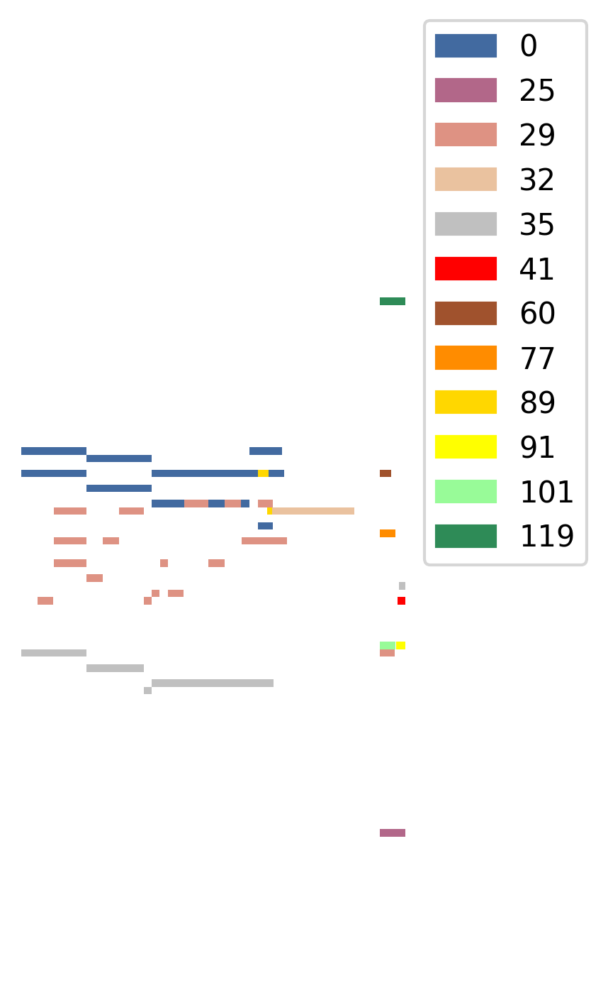

In [22]:
visualize(proposal, 'output.png') # visualize the proposed generation

In [23]:
print(ops.get_instruments(proposal)) # the number of notes for each instrument contained in the proposal

defaultdict(<class 'int'>, {29: 20, 0: 10, 35: 5, 128: 34, 89: 2, 32: 1, 60: 1, 77: 2, 101: 1, 119: 1, 25: 1, 91: 1, 41: 1})


**Accept** the proposed output

In [24]:
prompt = proposal
length += n

**Revise** the proposed output: delete an instrument from the proposed generation

In [25]:
instr = 128
candidate = ops.delete(proposal, lambda token: (token[2]-NOTE_OFFSET)//2**7 == instr)
output = ops.clip(ops.combine(candidate, melody), 0, length+n, clip_duration=True)
Audio(synthesize(fs, output))

In [26]:
# accept the revision
proposal = candidate

**Revise** the proposed output: revert to an earlier generation timepoint

In [27]:
reversion = length+2
candidate = ops.clip(proposal, 0, reversion, clip_duration=False)
output = ops.clip(ops.combine(candidate, melody), 0, length+n, clip_duration=True)
Audio(synthesize(fs, candidate))

In [28]:
# accept the revision
prompt = candidate
length = reversion

**Save** the proposed output

In [29]:
mid = events_to_midi(proposal)
mid.save('strawberry-1.mid')